In [2]:
# ============================================================
# PHASE 2: EXPLORATORY DATA ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings("ignore")

print("=" * 70)
print("PHASE 2: EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# Project paths
project_path = r"C:\Users\bhavy\flight-delay-domino-effect"

processed_path = os.path.join(project_path, "data", "processed")
raw_path = os.path.join(project_path, "data", "raw")

# Load cleaned completed flights
flights = pd.read_csv(
    os.path.join(processed_path, "cleaned_flights.csv")
)

# Load original dataset for cancellation/diversion analysis
all_flights = pd.read_csv(
    os.path.join(raw_path, "datasett.csv")
)

# Prepare EDA dataset
eda = flights.copy()

numeric_cols = [
    "DEP_DELAY", "ARR_DELAY", "DEP_TIME", "ARR_TIME",
    "CANCELLED", "DIVERTED", "TAXI_OUT", "TAXI_IN",
    "DISTANCE", "CARRIER_DELAY", "WEATHER_DELAY",
    "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY",
    "DAY_OF_WEEK", "MONTH"
]

for col in numeric_cols:
    if col in eda.columns:
        eda[col] = pd.to_numeric(eda[col], errors="coerce")

    if col in all_flights.columns:
        all_flights[col] = pd.to_numeric(
            all_flights[col], errors="coerce"
        )

eda["FL_DATE"] = pd.to_datetime(
    eda["FL_DATE"], errors="coerce"
)

# All records in cleaned_flights are already completed flights
completed = eda.copy()

completed["IS_ARR_DELAYED"] = (
    completed["ARR_DELAY"] > 15
).astype(int)

completed["IS_DEP_DELAYED"] = (
    completed["DEP_DELAY"] > 15
).astype(int)

print("\nDATASET OVERVIEW")
print("Original flights:", len(all_flights))
print("Completed flights:", len(completed))
print("Cancelled flights:", (all_flights["CANCELLED"] == 1).sum())
print("Diverted flights:", (all_flights["DIVERTED"] == 1).sum())
print("Dataset period:",
      completed["FL_DATE"].min(),
      "to",
      completed["FL_DATE"].max())

PHASE 2: EXPLORATORY DATA ANALYSIS

DATASET OVERVIEW
Original flights: 544003
Completed flights: 517222
Cancelled flights: 25635
Diverted flights: 1146
Dataset period: 2026-01-01 00:00:00 to 2026-01-31 00:00:00



1. ARRIVAL AND DEPARTURE DELAY DISTRIBUTIONS

Arrival Delay Statistics:
count    517222.00000
mean          6.41036
std          63.39614
min         -85.00000
25%         -18.00000
50%          -7.00000
75%           9.00000
max        3339.00000
Name: ARR_DELAY, dtype: float64

Departure Delay Statistics:
count    517222.000000
mean         12.975948
std          60.598006
min         -58.000000
25%          -7.000000
50%          -2.000000
75%           9.000000
max        3339.000000
Name: DEP_DELAY, dtype: float64

Arrival Delay Categories:
Early: 328335
On time / within 15 minutes: 84794
Delayed more than 15 minutes: 104093


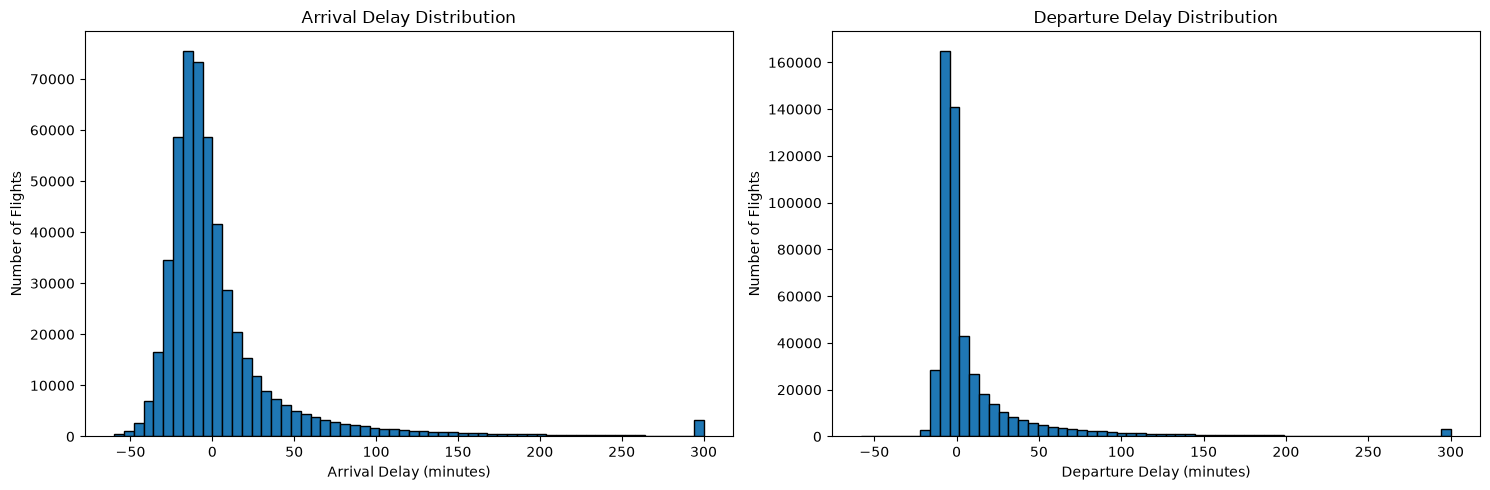


2. AIRPORT-WISE DELAY ANALYSIS

Top 10 Departure Airports:
        Total_Flights  Delayed_Flights  Average_Departure_Delay  Delay_Rate
ORIGIN                                                                     
TVC               241               95                    35.28       39.42
DLH               114               42                    51.52       36.84
RST               101               36                    46.26       35.64
AZO               136               47                    34.80       34.56
SBN               612              200                    39.07       32.68
CRW               236               77                    41.91       32.63
LAN               158               51                    52.70       32.28
MBS               174               54                    36.34       31.03
ASE               941              288                    31.83       30.61
FLL              8179             2502                    18.61       30.59

Top 10 Arrival Airports:
  

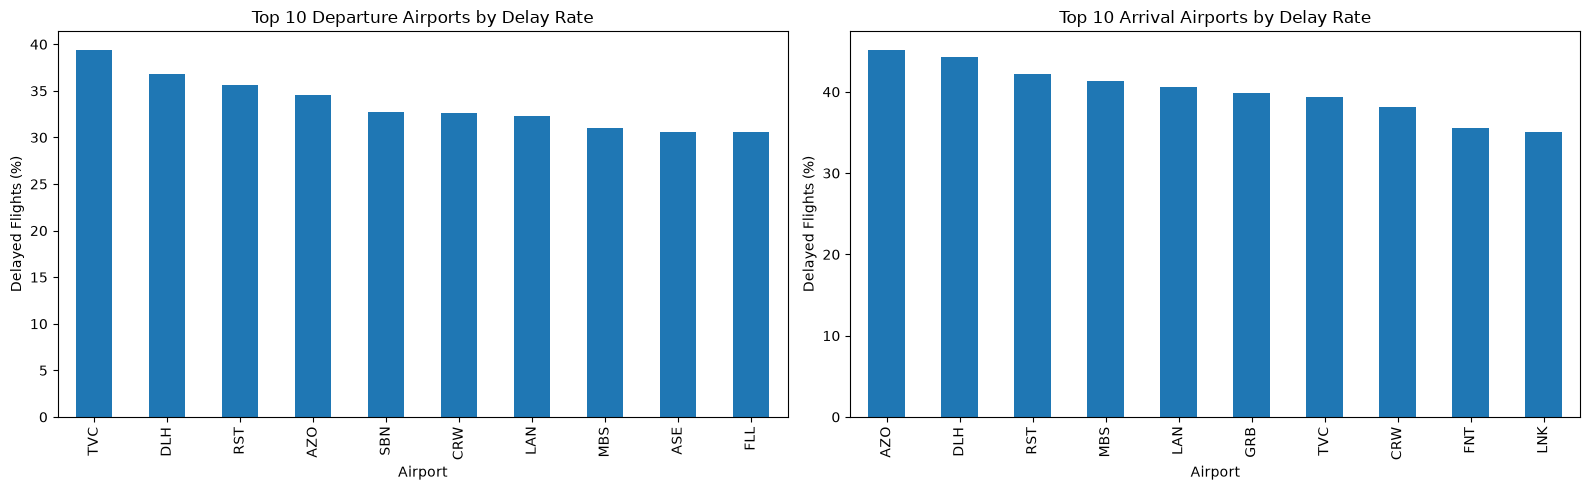


3. AIRLINE-WISE DELAY ANALYSIS
                   Total_Flights  Average_Departure_Delay  \
OP_UNIQUE_CARRIER                                           
B6                         16875                    19.90   
OH                         17247                    20.25   
AA                         69740                    20.72   
F9                         14817                    18.40   
OO                         63708                    18.65   
NK                         11047                    17.40   
G4                          8716                    15.10   
MQ                         22926                    10.22   
AS                         25799                    10.47   
DL                         75939                    10.73   
YX                         27112                     8.44   
UA                         62176                     9.14   
WN                        101120                     6.73   

                   Average_Arrival_Delay  Delayed_Fl

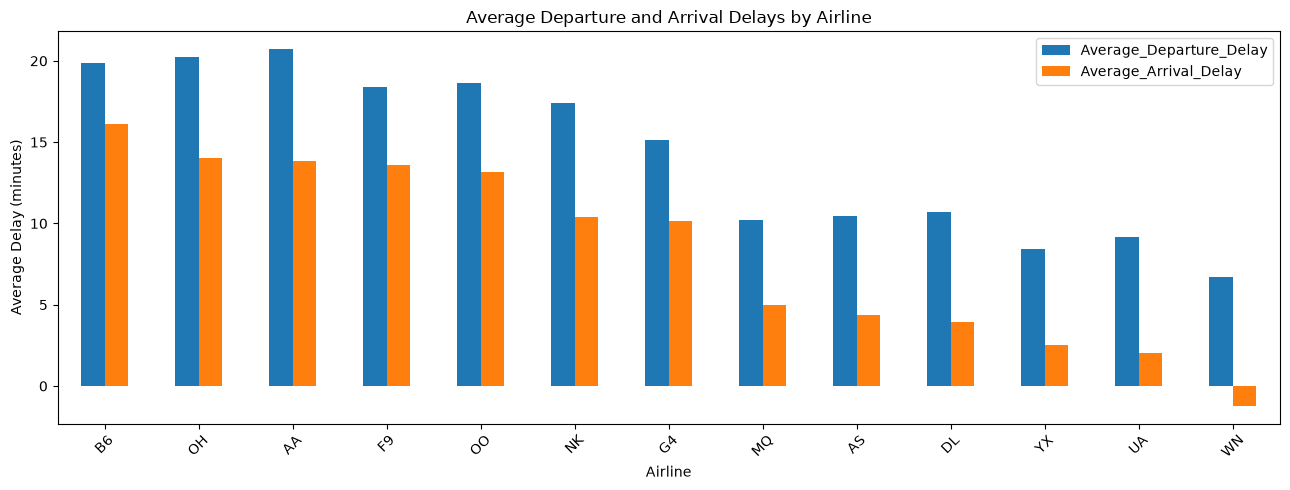


4. DAY-OF-WEEK DELAY ANALYSIS
             Total_Flights  Average_Departure_Delay  Average_Arrival_Delay
DAY_OF_WEEK                                                               
Sunday               68876                    19.32                  12.81
Monday               62650                    10.09                   1.37
Tuesday              64382                     8.15                   0.54
Wednesday            89903                    10.51                   3.79
Thursday             91718                    12.23                   6.12
Friday               74707                    13.48                   6.93
Saturday             64986                    17.71                  13.75


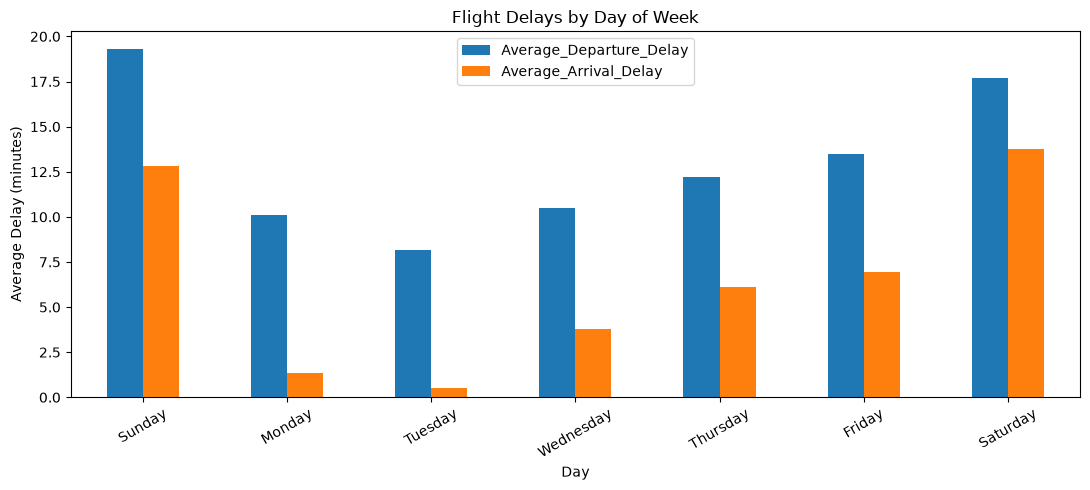


5. DEPARTURE TIME ANALYSIS
                  Total_Flights  Average_Departure_Delay  \
Departure_Period                                           
Morning                  212095                     5.00   
Afternoon                156190                    14.33   
Evening                  111855                    18.03   
Night                     37037                    37.60   

                  Average_Arrival_Delay  
Departure_Period                         
Morning                           -1.31  
Afternoon                          7.56  
Evening                           11.50  
Night                             30.40  


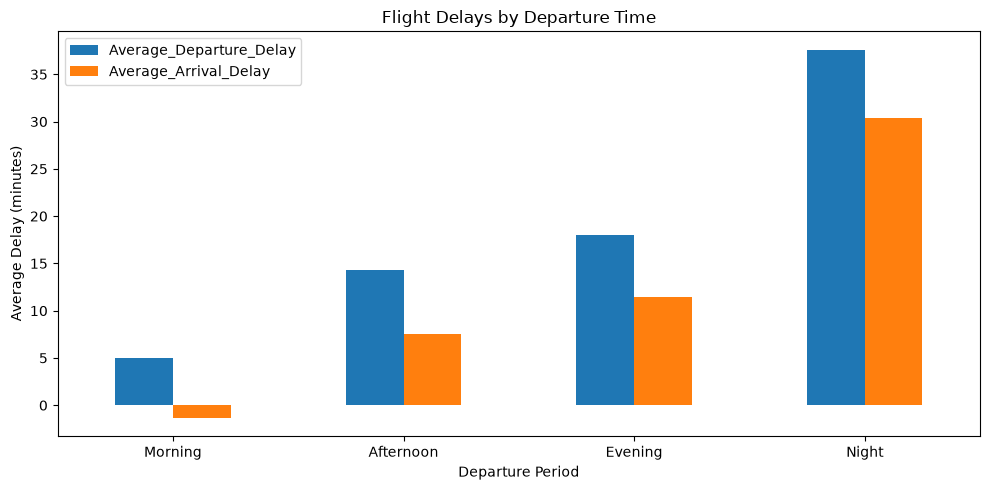


6. FLIGHT DELAY CAUSE ANALYSIS

Total Delay Minutes by Cause:
CARRIER_DELAY          3031178.0
LATE_AIRCRAFT_DELAY    2842019.0
NAS_DELAY              1465808.0
WEATHER_DELAY           776908.0
SECURITY_DELAY           11479.0
dtype: float64

Percentage Contribution by Cause:
CARRIER_DELAY          37.30
LATE_AIRCRAFT_DELAY    34.97
NAS_DELAY              18.04
WEATHER_DELAY           9.56
SECURITY_DELAY          0.14
dtype: float64


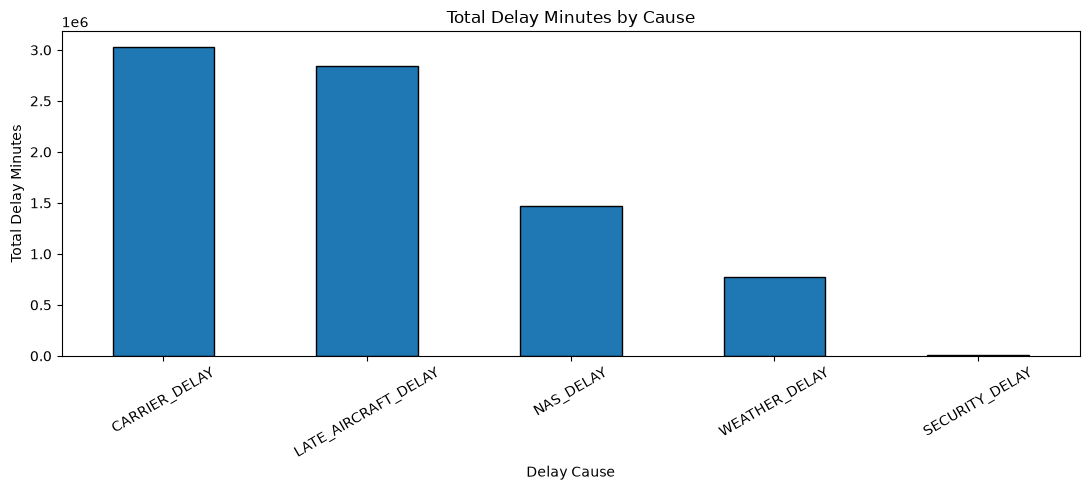


7. CANCELLATION AND DIVERSION ANALYSIS
Total flights: 544003
Cancelled flights: 25635
Cancellation rate (%): 4.71
Diverted flights: 1146
Diversion rate (%): 0.21

Airline-wise cancellation and diversion:
                   Total_Flights  Cancelled_Flights  Diverted_Flights  \
OP_UNIQUE_CARRIER                                                       
AA                         76772             6854.0             178.0   
AS                         26436              533.0             104.0   
B6                         18109             1201.0              33.0   
DL                         79198             3121.0             138.0   
F9                         15382              547.0              18.0   
G4                          8963              218.0              29.0   
MQ                         24155             1180.0              49.0   
NK                         11915              857.0              11.0   
OH                         19550             2267.0              

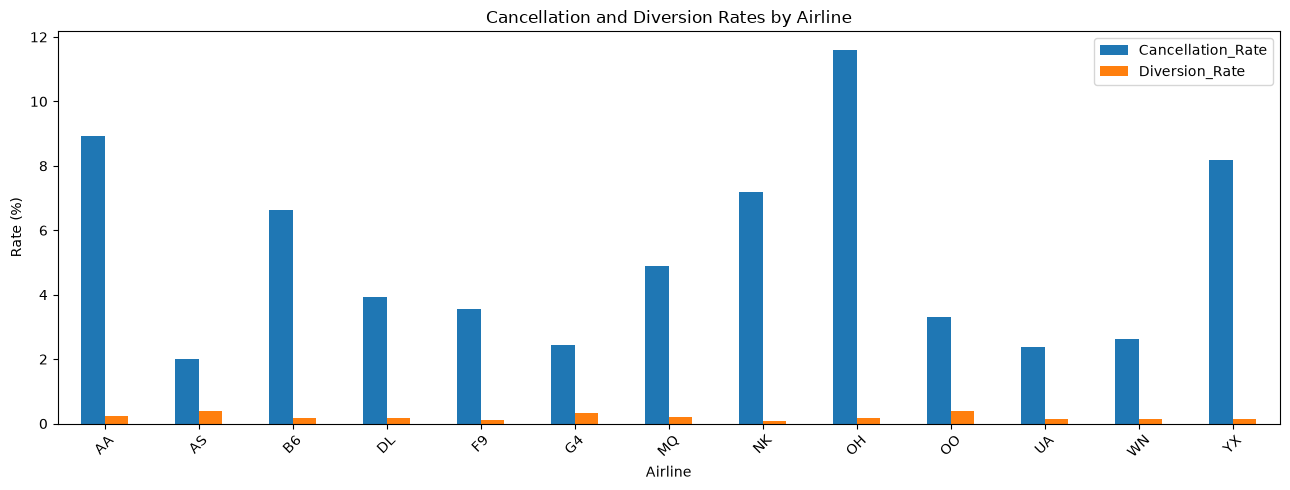


8. CORRELATION BETWEEN FLIGHT VARIABLES

Correlation Matrix:
                     DEP_DELAY  ARR_DELAY  TAXI_OUT  TAXI_IN  CARRIER_DELAY  \
DEP_DELAY                 1.00       0.97      0.09     0.04           0.68   
ARR_DELAY                 0.97       1.00      0.24     0.13           0.68   
TAXI_OUT                  0.09       0.24      1.00     0.04          -0.04   
TAXI_IN                   0.04       0.13      0.04     1.00          -0.03   
CARRIER_DELAY             0.68       0.68     -0.04    -0.03           1.00   
WEATHER_DELAY             0.38       0.40      0.06     0.02          -0.04   
NAS_DELAY                 0.05       0.16      0.38     0.27          -0.08   
SECURITY_DELAY            0.04       0.04     -0.00    -0.00          -0.01   
LATE_AIRCRAFT_DELAY       0.50       0.48     -0.11    -0.03          -0.06   
DISTANCE                  0.01      -0.01      0.00     0.04           0.01   

                     WEATHER_DELAY  NAS_DELAY  SECURITY_DELAY  \
DEP

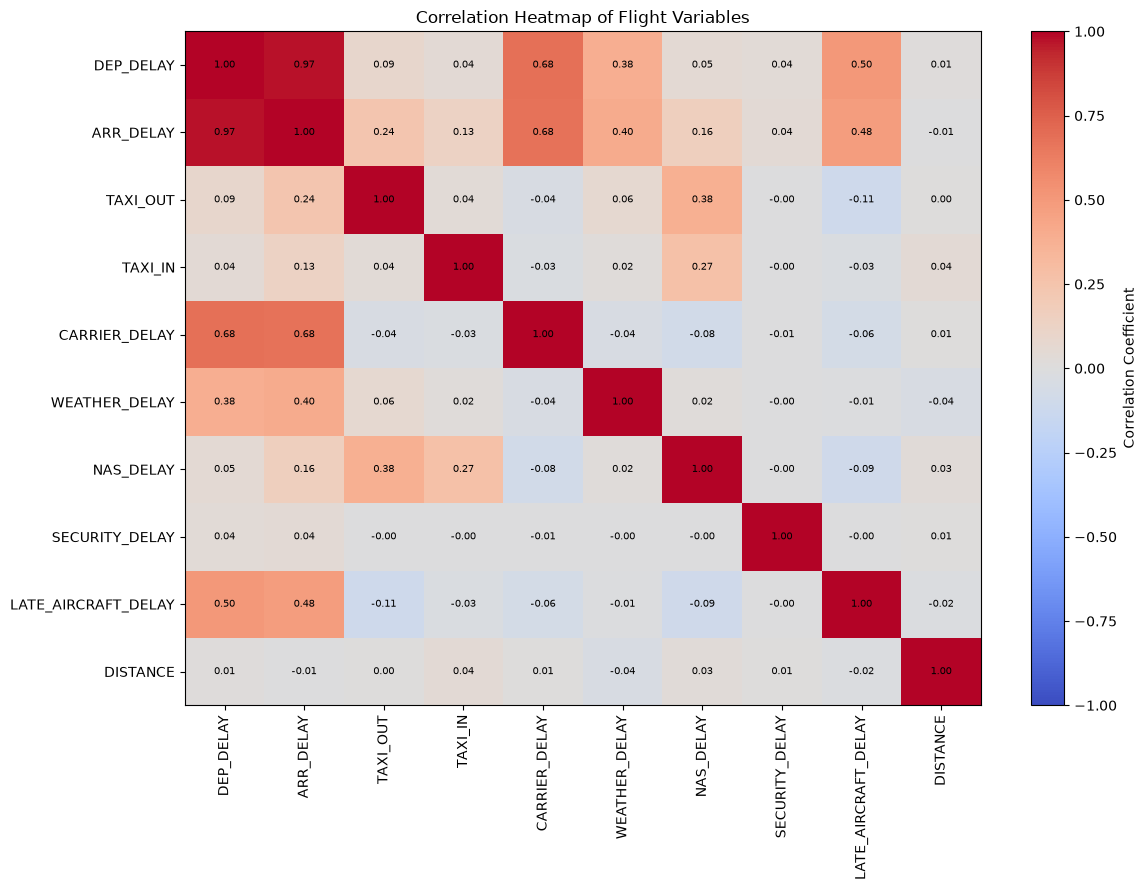


9. UNUSUAL OPERATIONAL PATTERNS

Outlier Summary:
    Variable  Lower_Bound  Upper_Bound  Outlier_Count  Outlier_Percentage
0  DEP_DELAY        -31.0         33.0          64626               12.49
1  ARR_DELAY        -58.5         49.5          47114                9.11
2   TAXI_OUT         -0.5         35.5          39024                7.54
3    TAXI_IN         -2.5         17.5          41038                7.93


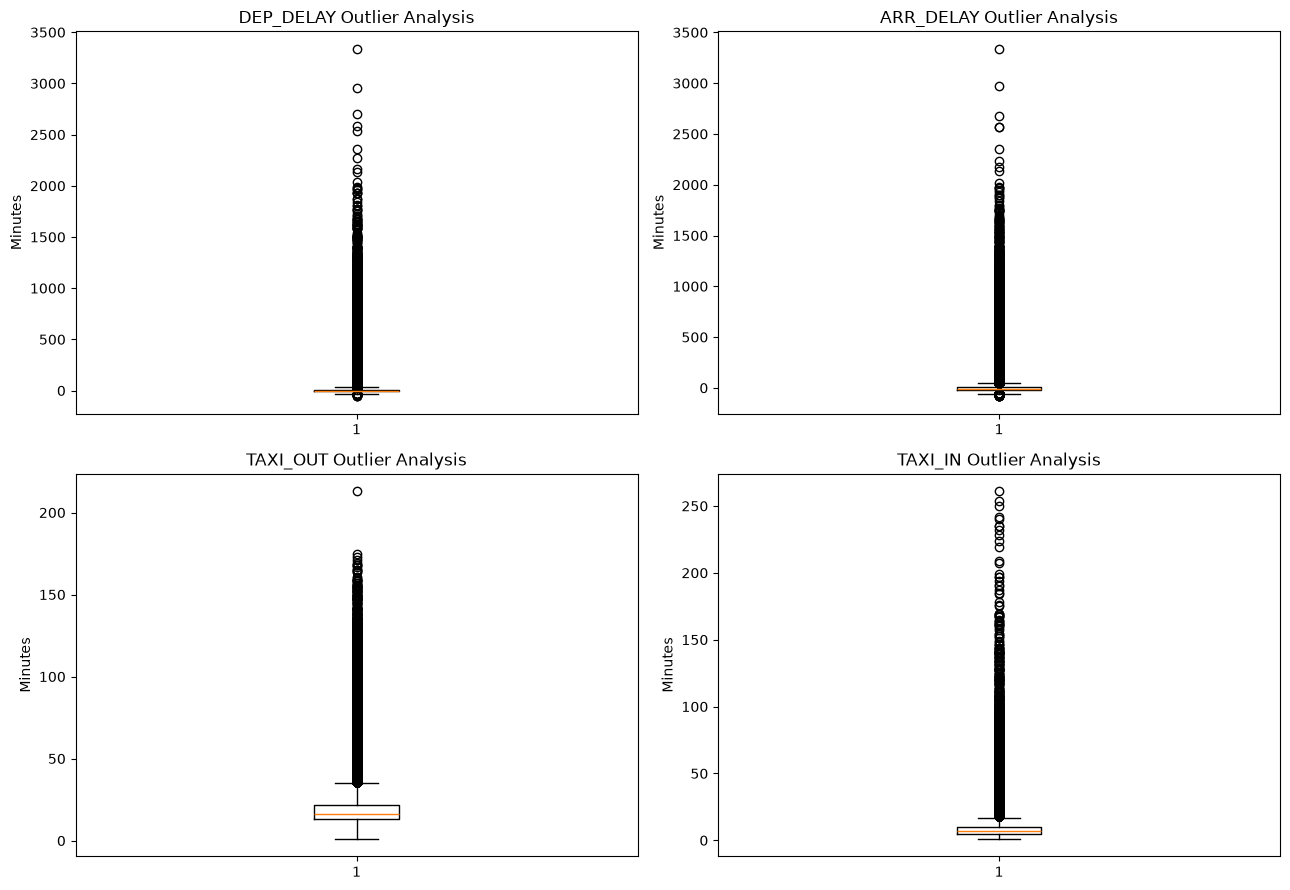


Top 10 Extreme Arrival Delays:
   FL_DATE OP_UNIQUE_CARRIER TAIL_NUM ORIGIN DEST  DEP_DELAY  ARR_DELAY
2026-01-29                AA   N873NN    SDF  DFW     3339.0     3339.0
2026-01-09                AA   N714US    AUS  PHL     2954.0     2975.0
2026-01-07                AA   N713UW    MCI  PHX     2706.0     2680.0
2026-01-08                AA   N760US    DSM  PHX     2539.0     2572.0
2026-01-11                AA   N356TX    STT  MIA     2581.0     2567.0
2026-01-08                AA   N338ST    AUS  CLT     2357.0     2351.0
2026-01-21                AA   N103NN    LAX  JFK     2270.0     2234.0
2026-01-03                AA   N995AN    SJU  PHL     2167.0     2177.0
2026-01-29                AA   N669AW    LAX  PHX     2137.0     2133.0
2026-01-01                AA   N844NN    ABQ  DFW     2036.0     2021.0

FINAL EDA SUMMARY

Original flights: 544003
Completed flights analyzed: 517222

Average arrival delay: 6.41 minutes
Average departure delay: 12.98 minutes
Arrival delay rate (

In [3]:
# ============================================================
# 1. ARRIVAL AND DEPARTURE DELAY DISTRIBUTIONS
# ============================================================

print("\n1. ARRIVAL AND DEPARTURE DELAY DISTRIBUTIONS")

print("\nArrival Delay Statistics:")
print(completed["ARR_DELAY"].describe())

print("\nDeparture Delay Statistics:")
print(completed["DEP_DELAY"].describe())

print("\nArrival Delay Categories:")

print("Early:",
      (completed["ARR_DELAY"] < 0).sum())

print("On time / within 15 minutes:",
      ((completed["ARR_DELAY"] >= 0) &
       (completed["ARR_DELAY"] <= 15)).sum())

print("Delayed more than 15 minutes:",
      (completed["ARR_DELAY"] > 15).sum())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(
    completed["ARR_DELAY"].dropna().clip(-60, 300),
    bins=60,
    edgecolor="black"
)

axes[0].set_title("Arrival Delay Distribution")
axes[0].set_xlabel("Arrival Delay (minutes)")
axes[0].set_ylabel("Number of Flights")

axes[1].hist(
    completed["DEP_DELAY"].dropna().clip(-60, 300),
    bins=60,
    edgecolor="black"
)

axes[1].set_title("Departure Delay Distribution")
axes[1].set_xlabel("Departure Delay (minutes)")
axes[1].set_ylabel("Number of Flights")

plt.tight_layout()
plt.show()


# ============================================================
# 2. AIRPORT-WISE DELAY ANALYSIS
# ============================================================

print("\n2. AIRPORT-WISE DELAY ANALYSIS")

# Departure airports
departure_data = completed.dropna(subset=["DEP_DELAY"]).copy()

origin_stats = departure_data.groupby("ORIGIN").agg(
    Total_Flights=("DEP_DELAY", "count"),
    Delayed_Flights=("IS_DEP_DELAYED", "sum"),
    Average_Departure_Delay=("DEP_DELAY", "mean")
)

origin_stats["Delay_Rate"] = (
    origin_stats["Delayed_Flights"] /
    origin_stats["Total_Flights"] * 100
)

origin_stats = origin_stats[
    origin_stats["Total_Flights"] >= 100
]

top_departure_airports = origin_stats.sort_values(
    "Delay_Rate", ascending=False
).head(10)

print("\nTop 10 Departure Airports:")
print(top_departure_airports.round(2))


# Arrival airports
arrival_data = completed.dropna(subset=["ARR_DELAY"]).copy()

dest_stats = arrival_data.groupby("DEST").agg(
    Total_Flights=("ARR_DELAY", "count"),
    Delayed_Flights=("IS_ARR_DELAYED", "sum"),
    Average_Arrival_Delay=("ARR_DELAY", "mean")
)

dest_stats["Delay_Rate"] = (
    dest_stats["Delayed_Flights"] /
    dest_stats["Total_Flights"] * 100
)

dest_stats = dest_stats[
    dest_stats["Total_Flights"] >= 100
]

top_arrival_airports = dest_stats.sort_values(
    "Delay_Rate", ascending=False
).head(10)

print("\nTop 10 Arrival Airports:")
print(top_arrival_airports.round(2))


fig, axes = plt.subplots(1, 2, figsize=(16, 5))

top_departure_airports["Delay_Rate"].plot(
    kind="bar", ax=axes[0]
)

axes[0].set_title("Top 10 Departure Airports by Delay Rate")
axes[0].set_ylabel("Delayed Flights (%)")
axes[0].set_xlabel("Airport")

top_arrival_airports["Delay_Rate"].plot(
    kind="bar", ax=axes[1]
)

axes[1].set_title("Top 10 Arrival Airports by Delay Rate")
axes[1].set_ylabel("Delayed Flights (%)")
axes[1].set_xlabel("Airport")

plt.tight_layout()
plt.show()


# ============================================================
# 3. AIRLINE-WISE DELAY ANALYSIS
# ============================================================

print("\n3. AIRLINE-WISE DELAY ANALYSIS")

airline_stats = arrival_data.groupby("OP_UNIQUE_CARRIER").agg(
    Total_Flights=("ARR_DELAY", "count"),
    Average_Departure_Delay=("DEP_DELAY", "mean"),
    Average_Arrival_Delay=("ARR_DELAY", "mean"),
    Delayed_Flights=("IS_ARR_DELAYED", "sum")
)

airline_stats["Delay_Rate"] = (
    airline_stats["Delayed_Flights"] /
    airline_stats["Total_Flights"] * 100
)

airline_stats = airline_stats[
    airline_stats["Total_Flights"] >= 100
].sort_values(
    "Average_Arrival_Delay", ascending=False
)

print(airline_stats.round(2))

airline_stats[
    ["Average_Departure_Delay", "Average_Arrival_Delay"]
].plot(kind="bar", figsize=(13, 5))

plt.title("Average Departure and Arrival Delays by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Delay (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# 4. DAY-OF-WEEK DELAY ANALYSIS
# ============================================================

print("\n4. DAY-OF-WEEK DELAY ANALYSIS")

weekday_names = {
    1: "Sunday",
    2: "Monday",
    3: "Tuesday",
    4: "Wednesday",
    5: "Thursday",
    6: "Friday",
    7: "Saturday"
}

weekday_stats = completed.groupby("DAY_OF_WEEK").agg(
    Total_Flights=("ARR_DELAY", "count"),
    Average_Departure_Delay=("DEP_DELAY", "mean"),
    Average_Arrival_Delay=("ARR_DELAY", "mean")
)

weekday_stats.index = weekday_stats.index.map(weekday_names)
weekday_stats = weekday_stats.dropna()

print(weekday_stats.round(2))

weekday_stats[
    ["Average_Departure_Delay", "Average_Arrival_Delay"]
].plot(kind="bar", figsize=(11, 5))

plt.title("Flight Delays by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Delay (minutes)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# ============================================================
# 5. DEPARTURE TIME ANALYSIS
# ============================================================

print("\n5. DEPARTURE TIME ANALYSIS")

def get_departure_period(value):

    if pd.isna(value):
        return np.nan

    value = int(value)

    hour = value // 100
    minute = value % 100

    if hour > 23 or minute > 59:
        return np.nan

    if 5 <= hour < 12:
        return "Morning"

    elif 12 <= hour < 17:
        return "Afternoon"

    elif 17 <= hour < 21:
        return "Evening"

    else:
        return "Night"


completed["Departure_Period"] = (
    completed["DEP_TIME"].apply(get_departure_period)
)

period_order = [
    "Morning", "Afternoon", "Evening", "Night"
]

period_stats = completed.groupby("Departure_Period").agg(
    Total_Flights=("ARR_DELAY", "count"),
    Average_Departure_Delay=("DEP_DELAY", "mean"),
    Average_Arrival_Delay=("ARR_DELAY", "mean")
).reindex(period_order)

print(period_stats.round(2))

period_stats[
    ["Average_Departure_Delay", "Average_Arrival_Delay"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Flight Delays by Departure Time")
plt.xlabel("Departure Period")
plt.ylabel("Average Delay (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# 6. FLIGHT DELAY CAUSE ANALYSIS
# ============================================================

print("\n6. FLIGHT DELAY CAUSE ANALYSIS")

delay_causes = [
    "CARRIER_DELAY",
    "WEATHER_DELAY",
    "NAS_DELAY",
    "SECURITY_DELAY",
    "LATE_AIRCRAFT_DELAY"
]

cause_data = completed[delay_causes].fillna(0)

cause_totals = cause_data.sum().sort_values(
    ascending=False
)

print("\nTotal Delay Minutes by Cause:")
print(cause_totals)

print("\nPercentage Contribution by Cause:")

if cause_totals.sum() > 0:
    print(
        (cause_totals / cause_totals.sum() * 100).round(2)
    )
else:
    print("No reported delay-cause minutes.")

cause_totals.plot(
    kind="bar",
    figsize=(11, 5),
    edgecolor="black"
)

plt.title("Total Delay Minutes by Cause")
plt.xlabel("Delay Cause")
plt.ylabel("Total Delay Minutes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# ============================================================
# 7. CANCELLATION AND DIVERSION ANALYSIS
# Uses the original dataset, NOT cleaned_flights
# ============================================================

print("\n7. CANCELLATION AND DIVERSION ANALYSIS")

total_flights = len(all_flights)

cancelled_count = (
    all_flights["CANCELLED"] == 1
).sum()

diverted_count = (
    all_flights["DIVERTED"] == 1
).sum()

print("Total flights:", total_flights)

print("Cancelled flights:", cancelled_count)

print("Cancellation rate (%):",
      round(cancelled_count / total_flights * 100, 2))

print("Diverted flights:", diverted_count)

print("Diversion rate (%):",
      round(diverted_count / total_flights * 100, 2))


# Airline-wise cancellation and diversion
airline_operational = all_flights.groupby(
    "OP_UNIQUE_CARRIER"
).agg(
    Total_Flights=("CANCELLED", "size"),
    Cancelled_Flights=("CANCELLED", "sum"),
    Diverted_Flights=("DIVERTED", "sum")
)

airline_operational["Cancellation_Rate"] = (
    airline_operational["Cancelled_Flights"] /
    airline_operational["Total_Flights"] * 100
)

airline_operational["Diversion_Rate"] = (
    airline_operational["Diverted_Flights"] /
    airline_operational["Total_Flights"] * 100
)

print("\nAirline-wise cancellation and diversion:")
print(airline_operational.round(2))

airline_operational[
    ["Cancellation_Rate", "Diversion_Rate"]
].plot(kind="bar", figsize=(13, 5))

plt.title("Cancellation and Diversion Rates by Airline")
plt.xlabel("Airline")
plt.ylabel("Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# 8. CORRELATION ANALYSIS
# ============================================================

print("\n8. CORRELATION BETWEEN FLIGHT VARIABLES")

correlation_columns = [
    "DEP_DELAY",
    "ARR_DELAY",
    "TAXI_OUT",
    "TAXI_IN",
    "CARRIER_DELAY",
    "WEATHER_DELAY",
    "NAS_DELAY",
    "SECURITY_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "DISTANCE"
]

# Pairwise correlations handle missing values per variable pair
correlation_data = completed[correlation_columns]

correlation_matrix = correlation_data.corr(
    method="pearson"
)

print("\nCorrelation Matrix:")
print(correlation_matrix.round(2))

plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Correlation Heatmap of Flight Variables")

for i in range(len(correlation_columns)):
    for j in range(len(correlation_columns)):
        value = correlation_matrix.iloc[i, j]

        if pd.notna(value):
            plt.text(
                j, i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=7
            )

plt.tight_layout()
plt.show()


# ============================================================
# 9. UNUSUAL OPERATIONAL PATTERNS AND OUTLIERS
# ============================================================

print("\n9. UNUSUAL OPERATIONAL PATTERNS")

outlier_columns = [
    "DEP_DELAY",
    "ARR_DELAY",
    "TAXI_OUT",
    "TAXI_IN"
]

outlier_summary = []

for col in outlier_columns:

    values = completed[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) |
        (values > upper_bound)
    ]

    outlier_summary.append({
        "Variable": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (
            len(outliers) / len(values) * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

print("\nOutlier Summary:")
print(outlier_summary.round(2))


fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flatten(), outlier_columns):

    ax.boxplot(
        completed[col].dropna(),
        showfliers=True
    )

    ax.set_title(f"{col} Outlier Analysis")
    ax.set_ylabel("Minutes")

plt.tight_layout()
plt.show()


# Top 10 extreme arrival delays
extreme_delays = completed.nlargest(
    10, "ARR_DELAY"
)[[
    "FL_DATE",
    "OP_UNIQUE_CARRIER",
    "TAIL_NUM",
    "ORIGIN",
    "DEST",
    "DEP_DELAY",
    "ARR_DELAY"
]]

print("\nTop 10 Extreme Arrival Delays:")
print(extreme_delays.to_string(index=False))


# ============================================================
# 10. FINAL EDA SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL EDA SUMMARY")
print("=" * 70)

print("\nOriginal flights:", len(all_flights))
print("Completed flights analyzed:", len(completed))

print("\nAverage arrival delay:",
      round(completed["ARR_DELAY"].mean(), 2),
      "minutes")

print("Average departure delay:",
      round(completed["DEP_DELAY"].mean(), 2),
      "minutes")

print("Arrival delay rate (>15 min):",
      round(completed["IS_ARR_DELAYED"].mean() * 100, 2),
      "%")

print("Departure delay rate (>15 min):",
      round(completed["IS_DEP_DELAYED"].mean() * 100, 2),
      "%")

print("Cancellation rate:",
      round(cancelled_count / total_flights * 100, 2),
      "%")

print("Diversion rate:",
      round(diverted_count / total_flights * 100, 2),
      "%")

print("\nDataset period:",
      completed["FL_DATE"].min(),
      "to",
      completed["FL_DATE"].max())

print("\nEDA COMPLETED SUCCESSFULLY!")
print("=" * 70)